# Assignment 9


In [1]:
import os
import re
import cv2
import pytesseract
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont
from datetime import datetime

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data/medicine_labels', exist_ok=True)
print("Libraries imported successfully!")


Libraries imported successfully!


## Question 1


In [2]:
def create_medicine_label(filename, brand, generic, strength, batch, mfg, exp, indications, storage, warning, primary_color='#2980B9'):
    img = Image.new('RGB', (640, 380), color='#FFFFFF')
    draw = ImageDraw.Draw(img)

    draw.rectangle([(8, 8), (632, 372)], outline='#1A252F', width=3)
    draw.rectangle([(8, 8), (632, 60)], fill=primary_color)
    draw.text((25, 20), "Rx PHARMACEUTICAL HEALTHCARE - DISPENSE AS WRITTEN", fill='white')

    draw.text((25, 75), f"{brand.upper()}", fill='#922B21')
    draw.text((25, 110), f"Active Ingredient: {generic}", fill='#1B2631')
    draw.text((25, 135), f"Strength / Dosage: {strength}", fill='#0E6251')

    draw.text((25, 165), f"Indications: {indications}", fill='#2C3E50')
    draw.text((25, 190), f"Storage: {storage}", fill='#2C3E50')

    draw.rectangle([(18, 218), (622, 268)], outline='#C0392B', width=2, fill='#FDEDEC')
    draw.text((25, 226), f"WARNING: {warning}", fill='#78281F')

    draw.rectangle([(8, 280), (632, 372)], fill='#EAEDED')
    draw.text((25, 295), f"Batch No: {batch}", fill='#2C3E50')
    draw.text((25, 325), f"Mfg Date: {mfg}", fill='#2C3E50')
    draw.text((280, 325), f"Expiry Date: {exp}", fill='#78281F')

    img.save(filename)
    return filename

dataset_catalog = [
    {
        'filename': 'data/medicine_labels/panadol.png',
        'brand': 'Panadol Extra',
        'generic': 'Paracetamol / Caffeine',
        'strength': '500 mg / 65 mg Tablets',
        'batch': 'BN88201',
        'mfg': '01/2024',
        'exp': '12/2027',
        'indications': 'Relief of headache, migraine, backache, and fever',
        'storage': 'Store below 25C in a dry place. Protect from light.',
        'warning': 'Do not take with other paracetamol products. Max 4000mg/24hr.',
        'color': '#1F618D'
    },
    {
        'filename': 'data/medicine_labels/amoxicillin.png',
        'brand': 'Amoxil Forte',
        'generic': 'Amoxicillin Trihydrate',
        'strength': '250 mg / 5ml Suspension',
        'batch': 'BN41920',
        'mfg': '03/2021',
        'exp': '05/2023',
        'indications': 'Treatment of bacterial respiratory and urinary infections',
        'storage': 'Refrigerate between 2C and 8C. Do not freeze.',
        'warning': 'Shake well before use. Discard unused suspension after 14 days.',
        'color': '#117A65'
    },
    {
        'filename': 'data/medicine_labels/atorvastatin.png',
        'brand': 'Lipitor',
        'generic': 'Atorvastatin Calcium',
        'strength': '20 mg Film-Coated Tablets',
        'batch': 'BN92110',
        'mfg': '06/2024',
        'exp': '08/2027',
        'indications': 'Lowers LDL cholesterol and reduces cardiovascular risk',
        'storage': 'Store at controlled room temperature 20C to 25C.',
        'warning': 'Avoid grapefruit juice during treatment. Contraindicated in active liver disease.',
        'color': '#6C3483'
    }
]

for med in dataset_catalog:
    create_medicine_label(
        med['filename'], med['brand'], med['generic'], med['strength'],
        med['batch'], med['mfg'], med['exp'], med['indications'],
        med['storage'], med['warning'], med['color']
    )

print(f"Generated {len(dataset_catalog)} pharmaceutical label images in 'data/medicine_labels/'")


Generated 3 pharmaceutical label images in 'data/medicine_labels/'


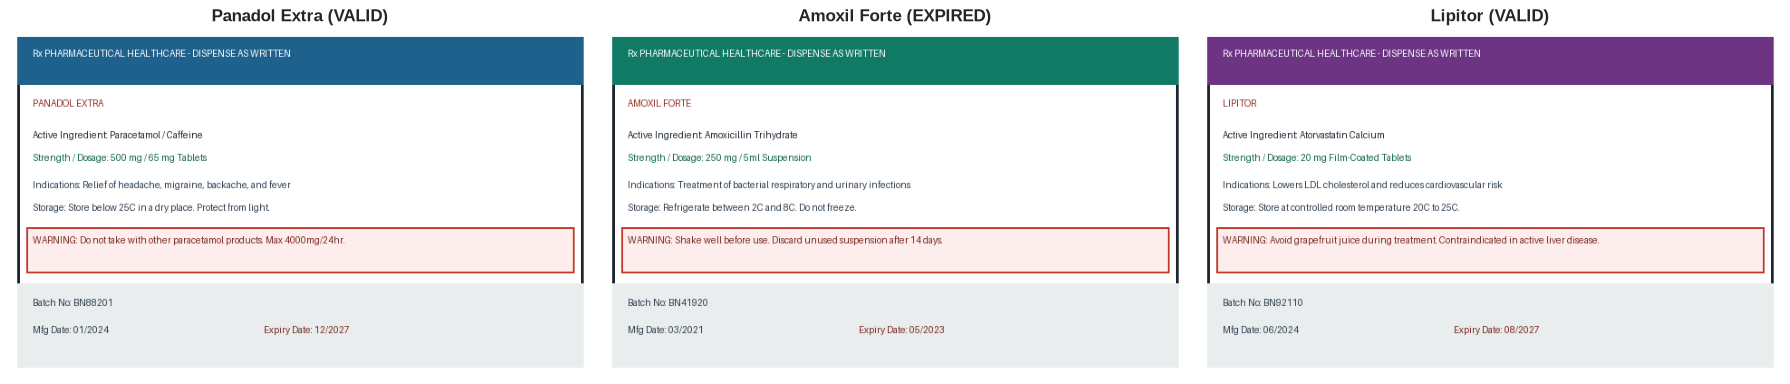

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, med in zip(axes, dataset_catalog):
    im = Image.open(med['filename'])
    ax.imshow(im)
    ax.set_title(f"{med['brand']} ({'EXPIRED' if '2023' in med['exp'] else 'VALID'})", fontsize=12, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()


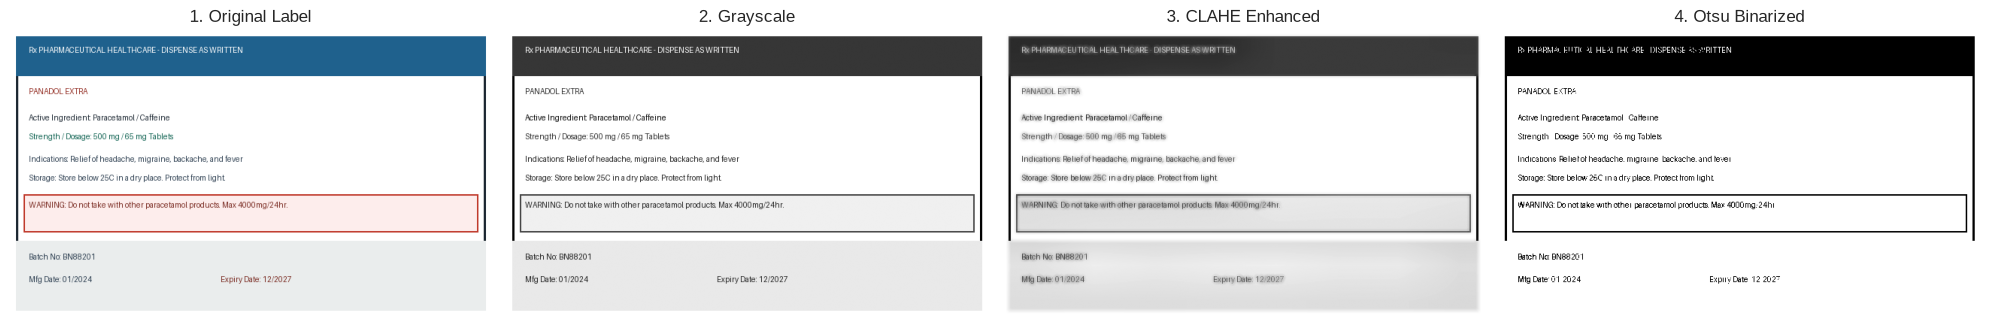

In [4]:
def preprocess_medicine_label(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    denoised = cv2.bilateralFilter(gray, 9, 75, 75)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(denoised)

    _, binarized = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    return img, gray, enhanced, binarized

orig_img, gray_img, enh_img, bin_img = preprocess_medicine_label('data/medicine_labels/panadol.png')

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
axs[0].set_title("1. Original Label")
axs[1].imshow(gray_img, cmap='gray')
axs[1].set_title("2. Grayscale")
axs[2].imshow(enh_img, cmap='gray')
axs[2].set_title("3. CLAHE Enhanced")
axs[3].imshow(bin_img, cmap='gray')
axs[3].set_title("4. Otsu Binarized")
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()


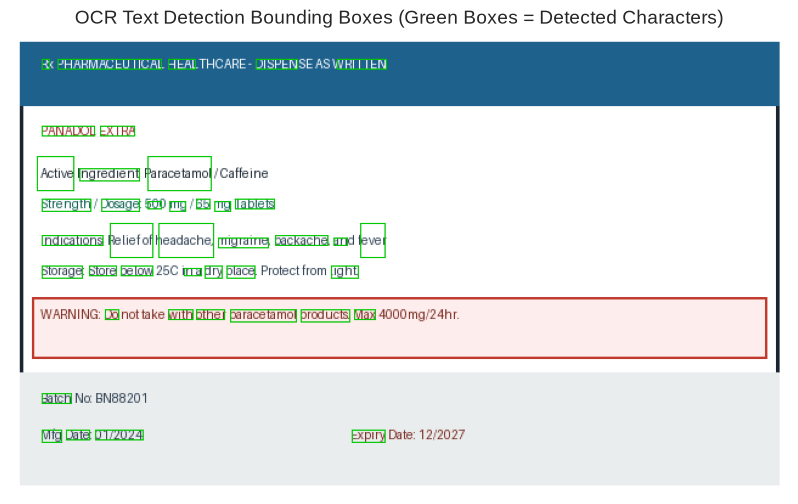

Extracted Raw OCR Text:
--------------------------------------------------
x PHARMACEUTICAL HEAL THOARE” DISPENSE ASWRITTEN

PANADOL EXTRA

Active Ingredient Paracetamol Caffeine

Strength Dosage’ 500 mg /65 mq Tablets

Indications Reliefof headache, migraine, backache, an fever

Storage: Store below 25C ina dry place, Protect fom light,

WARNING. Do nottake with other paracetamol preducts Max 4000mg/24ht

Batoh Ne: BNBB201

Mig Date 01/2024 Expiry Date 12/2027


--------------------------------------------------


In [5]:
def extract_text_and_bounding_boxes(image_path):
    orig, gray, enhanced, binarized = preprocess_medicine_label(image_path)

    ocr_data = pytesseract.image_to_data(enhanced, output_type=pytesseract.Output.DATAFRAME)
    ocr_data = ocr_data[ocr_data.text.notnull() & (ocr_data.text.str.strip() != '')]

    full_text = pytesseract.image_to_string(enhanced)

    annotated = orig.copy()
    for _, row in ocr_data.iterrows():
        x, y, w, h = int(row['left']), int(row['top']), int(row['width']), int(row['height'])
        conf = int(row['conf'])
        if conf > 40:
            cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 200, 0), 1)

    return full_text, ocr_data, annotated

full_text_panadol, ocr_df, bbox_img = extract_text_and_bounding_boxes('data/medicine_labels/panadol.png')

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(bbox_img, cv2.COLOR_BGR2RGB))
plt.title("OCR Text Detection Bounding Boxes (Green Boxes = Detected Characters)", fontsize=14)
plt.axis('off')
plt.show()

print("Extracted Raw OCR Text:\n" + "-" * 50)
print(full_text_panadol)
print("-" * 50)


In [6]:
class MedicineLabelCognitiveParser:
    def __init__(self, current_year=2026, current_month=11):
        self.current_year = current_year
        self.current_month = current_month

    def parse(self, raw_text):
        entities = {
            'brand_name': 'Unknown Pharmaceutical',
            'generic_name': 'Not identified',
            'strength': 'Not identified',
            'batch_number': 'N/A',
            'mfg_date': 'N/A',
            'expiry_date': 'N/A',
            'is_expired': False,
            'indications': 'General therapeutic use',
            'storage': 'Room temperature',
            'warnings': 'Follow physician guidance'
        }

        lines = [l.strip() for l in raw_text.split('\n') if l.strip()]

        for line in lines:
            if not any(skip in line.upper() for skip in ['RX', 'PHARMACEUTICAL', 'HEALTHCARE', 'DISPENSE', 'ONLY']):
                if len(line) > 3 and not any(k in line.lower() for k in ['generic', 'active', 'strength', 'batch']):
                    entities['brand_name'] = line.title()
                    break

        gen_match = re.search(r'(?:Active Ingredient|Generic)[:\s]+([^\r\n]+)', raw_text, re.IGNORECASE)
        if gen_match:
            entities['generic_name'] = gen_match.group(1).strip()

        strength_match = re.search(r'(?:Strength|Dosage)[:\s]+([0-9]+\s*(?:mg|ml|mcg|g)[^\r\n]*)', raw_text, re.IGNORECASE)
        if strength_match:
            entities['strength'] = strength_match.group(1).strip()
        else:
            num_match = re.search(r'([0-9]+\s*(?:mg|ml|mcg)\s*(?:Tablets|Suspension|Capsules)?)', raw_text, re.IGNORECASE)
            if num_match:
                entities['strength'] = num_match.group(1).strip()

        batch_match = re.search(r'(?:Batch No|BN|Lot)[:\s]*([A-Z0-9]+)', raw_text, re.IGNORECASE)
        if batch_match:
            entities['batch_number'] = batch_match.group(1).strip()

        mfg_match = re.search(r'(?:Mfg Date|Mfg)[:\s]*([0-9]{2}/[0-9]{4})', raw_text, re.IGNORECASE)
        if mfg_match:
            entities['mfg_date'] = mfg_match.group(1).strip()

        exp_match = re.search(r'(?:Expiry Date|Exp)[:\s]*([0-9]{2}/[0-9]{4})', raw_text, re.IGNORECASE)
        if exp_match:
            exp_str = exp_match.group(1).strip()
            entities['expiry_date'] = exp_str
            try:
                exp_m, exp_y = [int(x) for x in exp_str.split('/')]
                if exp_y < self.current_year or (exp_y == self.current_year and exp_m < self.current_month):
                    entities['is_expired'] = True
            except:
                pass

        ind_match = re.search(r'Indications[:\s]+([^\r\n]+)', raw_text, re.IGNORECASE)
        if ind_match:
            entities['indications'] = ind_match.group(1).strip()

        storage_match = re.search(r'Storage[:\s]+([^\r\n]+)', raw_text, re.IGNORECASE)
        if storage_match:
            entities['storage'] = storage_match.group(1).strip()

        warn_match = re.search(r'WARNING[:\s]+([^\r\n]+)', raw_text, re.IGNORECASE)
        if warn_match:
            entities['warnings'] = warn_match.group(1).strip()

        return entities

parser = MedicineLabelCognitiveParser(current_year=2026, current_month=11)
panadol_entities = parser.parse(full_text_panadol)

print("Parsed Semantic Knowledge Card:")
for k, v in panadol_entities.items():
    print(f"  • {k.replace('_', ' ').title():<22}: {v}")


Parsed Semantic Knowledge Card:
  • Brand Name            : Panadol Extra
  • Generic Name          : Paracetamol Caffeine
  • Strength              : 500 mg
  • Batch Number          : BB201
  • Mfg Date              : N/A
  • Expiry Date           : 12/2027
  • Is Expired            : False
  • Indications           : Reliefof headache, migraine, backache, an fever
  • Storage               : Store below 25C ina dry place, Protect fom light,
  • Warnings              : Follow physician guidance


In [7]:
class MedicineCognitiveAssistant:
    def __init__(self, label_image_path):
        self.image_path = label_image_path
        self.parser = MedicineLabelCognitiveParser(current_year=2026, current_month=11)
        self.raw_text, self.ocr_data, self.annotated_img = extract_text_and_bounding_boxes(label_image_path)
        self.entities = self.parser.parse(self.raw_text)

    def answer_query(self, query):
        q = query.lower()

        if any(w in q for w in ['expired', 'expiry', 'safe to use', 'outdated', 'date']):
            if self.entities['is_expired']:
                return (
                    f"⚠️ [CRITICAL SAFETY ALERT] THIS MEDICINE IS EXPIRED!\n"
                    f"• Stated Expiry Date: {self.entities['expiry_date']}\n"
                    f"• Current Date: November 2026\n"
                    f"• Recommendation: DO NOT CONSUME. Chemical degradation may reduce efficacy or produce toxic byproducts. Please safely dispose of this medication."
                )
            else:
                return (
                    f"✅ [VALID & ACTIVE] This medicine is within its valid shelf life.\n"
                    f"• Expiry Date: {self.entities['expiry_date']}\n"
                    f"• Batch Number: {self.entities['batch_number']}\n"
                    f"• Status: Safe for consumption in accordance with prescribed dosages."
                )

        elif any(w in q for w in ['dosage', 'strength', 'how much', 'dose', 'tablets']):
            dose_num = re.findall(r'(\d+)\s*(?:mg|tablets?)', q)
            overdose_flag = ""
            if dose_num and int(dose_num[0]) >= 2000 and 'mg' in q:
                overdose_flag = (
                    f"\n⚠️ WARNING: The requested dose ({dose_num[0]} mg) approaches or exceeds single-dose safety boundaries! "
                    f"Strictly adhere to packaging instructions: {self.entities['warnings']}"
                )
            return (
                f"💊 [DOSAGE SPECIFICATION]\n"
                f"• Medicine: {self.entities['brand_name']}\n"
                f"• Stated Strength: {self.entities['strength']}\n"
                f"• Guidance: Follow recommended label directions. {overdose_flag}"
            )

        elif any(w in q for w in ['storage', 'store', 'fridge', 'refrigerator', 'temperature', 'keep']):
            return (
                f"🌡️ [STORAGE INSTRUCTIONS]\n"
                f"• Recommendation: {self.entities['storage']}\n"
                f"• Note: Proper storage prevents pharmaceutical degradation."
            )

        elif any(w in q for w in ['what is this', 'used for', 'indications', 'purpose', 'cure', 'treat']):
            return (
                f"📋 [THERAPEUTIC INDICATIONS]\n"
                f"• Brand Name: {self.entities['brand_name']}\n"
                f"• Active Ingredient: {self.entities['generic_name']}\n"
                f"• Clinical Purpose: {self.entities['indications']}"
            )

        elif any(w in q for w in ['warning', 'precaution', 'side effect', 'danger', 'avoid']):
            return (
                f"🛡️ [SAFETY ADVISORY & WARNINGS]\n"
                f"• Label Warning: {self.entities['warnings']}\n"
                f"• Always consult a registered physician or pharmacist if symptoms persist."
            )

        else:
            return (
                f"ℹ️ [LABEL SUMMARY]\n"
                f"• Brand: {self.entities['brand_name']}\n"
                f"• Formula: {self.entities['generic_name']} ({self.entities['strength']})\n"
                f"• Expiry: {self.entities['expiry_date']} ({'EXPIRED' if self.entities['is_expired'] else 'Valid'})\n"
                f"• Instructions: {self.entities['indications']}"
            )


In [8]:
assistant_panadol = MedicineCognitiveAssistant('data/medicine_labels/panadol.png')
assistant_amoxil = MedicineCognitiveAssistant('data/medicine_labels/amoxicillin.png')

test_suite = [
    (assistant_panadol, "What is this medicine used for?"),
    (assistant_panadol, "How should I store this medicine?"),
    (assistant_panadol, "Can I take 2500 mg at once for severe fever?"),
    (assistant_amoxil, "Is this amoxicillin suspension safe to use right now?"),
    (assistant_amoxil, "What are the storage requirements and warnings?")
]

print("=" * 80)
print("INTERACTIVE COGNITIVE MEDICINE ASSISTANT TEST SESSION")
print("=" * 80)

for asst, query in test_suite:
    print(f"\n[USER QUERY]: \"{query}\" (Bottle: {asst.entities['brand_name']})")
    print(asst.answer_query(query))
    print("-" * 80)


INTERACTIVE COGNITIVE MEDICINE ASSISTANT TEST SESSION

[USER QUERY]: "What is this medicine used for?" (Bottle: Panadol Extra)
📋 [THERAPEUTIC INDICATIONS]
• Brand Name: Panadol Extra
• Active Ingredient: Paracetamol Caffeine
• Clinical Purpose: Reliefof headache, migraine, backache, an fever
--------------------------------------------------------------------------------

[USER QUERY]: "How should I store this medicine?" (Bottle: Panadol Extra)
🌡️ [STORAGE INSTRUCTIONS]
• Recommendation: Store below 25C ina dry place, Protect fom light,
• Note: Proper storage prevents pharmaceutical degradation.
--------------------------------------------------------------------------------

[USER QUERY]: "Can I take 2500 mg at once for severe fever?" (Bottle: Panadol Extra)
ℹ️ [LABEL SUMMARY]
• Brand: Panadol Extra
• Formula: Paracetamol Caffeine (500 mg)
• Expiry: 12/2027 (Valid)
• Instructions: Reliefof headache, migraine, backache, an fever
---------------------------------------------------------

## Question 2


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

emotions = ['Happy', 'Sad', 'Angry', 'Surprised', 'Fearful', 'Neutral']

np.random.seed(42)
N_PER_CLASS = 200

data_rows = []
for em in emotions:
    for _ in range(N_PER_CLASS):
        if em == 'Happy':
            mouth_curve = np.random.normal(0.75, 0.12)
            mouth_width = np.random.normal(0.65, 0.10)
            brow_furrow = np.random.normal(0.15, 0.08)
            eye_openness = np.random.normal(0.55, 0.08)
            tension = np.random.normal(0.20, 0.08)
        elif em == 'Sad':
            mouth_curve = np.random.normal(-0.65, 0.12)
            mouth_width = np.random.normal(0.35, 0.08)
            brow_furrow = np.random.normal(0.60, 0.10)
            eye_openness = np.random.normal(0.30, 0.07)
            tension = np.random.normal(0.40, 0.10)
        elif em == 'Angry':
            mouth_curve = np.random.normal(-0.35, 0.12)
            mouth_width = np.random.normal(0.38, 0.08)
            brow_furrow = np.random.normal(0.85, 0.08)
            eye_openness = np.random.normal(0.35, 0.08)
            tension = np.random.normal(0.85, 0.08)
        elif em == 'Surprised':
            mouth_curve = np.random.normal(0.10, 0.10)
            mouth_width = np.random.normal(0.85, 0.08)
            brow_furrow = np.random.normal(0.05, 0.05)
            eye_openness = np.random.normal(0.90, 0.06)
            tension = np.random.normal(0.30, 0.08)
        elif em == 'Fearful':
            mouth_curve = np.random.normal(-0.20, 0.10)
            mouth_width = np.random.normal(0.70, 0.10)
            brow_furrow = np.random.normal(0.75, 0.10)
            eye_openness = np.random.normal(0.80, 0.08)
            tension = np.random.normal(0.80, 0.09)
        else:
            mouth_curve = np.random.normal(0.00, 0.08)
            mouth_width = np.random.normal(0.45, 0.07)
            brow_furrow = np.random.normal(0.25, 0.07)
            eye_openness = np.random.normal(0.50, 0.06)
            tension = np.random.normal(0.25, 0.07)

        data_rows.append({
            'mouth_curve': mouth_curve,
            'mouth_width': mouth_width,
            'brow_furrow': brow_furrow,
            'eye_openness': eye_openness,
            'tension': tension,
            'emotion': em
        })

df_emotions = pd.DataFrame(data_rows)
print(f"Dataset Shape: {df_emotions.shape}")
display(df_emotions.head())


Dataset Shape: (1200, 6)


,mouth_curve,mouth_width,brow_furrow,eye_openness,tension,emotion
0,0.809606,0.636174,0.201815,0.671842,0.181268,Happy
1,0.721904,0.807921,0.211395,0.512442,0.243405,Happy
2,0.694390,0.603427,0.169357,0.396938,0.062007,Happy
3,0.682525,0.548717,0.175140,0.477358,0.087016,Happy
4,0.925878,0.627422,0.155402,0.436020,0.156449,Happy


Facial Emotion Classifier Test Accuracy: 99.67%

Classification Report:
              precision    recall  f1-score   support

       Angry       1.00      0.98      0.99        50
     Fearful       1.00      1.00      1.00        50
       Happy       1.00      1.00      1.00        50
     Neutral       1.00      1.00      1.00        50
         Sad       0.98      1.00      0.99        50
   Surprised       1.00      1.00      1.00        50

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



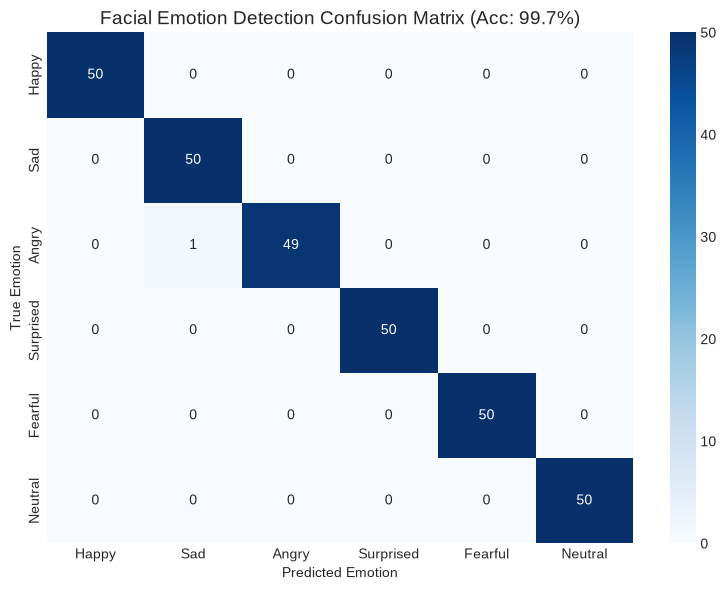

In [10]:
X_feat = df_emotions[['mouth_curve', 'mouth_width', 'brow_furrow', 'eye_openness', 'tension']].values
y_labels = df_emotions['emotion'].values

X_train, X_test, y_train, y_test = train_test_split(X_feat, y_labels, test_size=0.25, random_state=42, stratify=y_labels)

emotion_classifier = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
emotion_classifier.fit(X_train, y_train)

y_pred = emotion_classifier.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Facial Emotion Classifier Test Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=emotions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotions, yticklabels=emotions)
plt.title(f"Facial Emotion Detection Confusion Matrix (Acc: {acc*100:.1f}%)", fontsize=14)
plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.tight_layout()
plt.show()


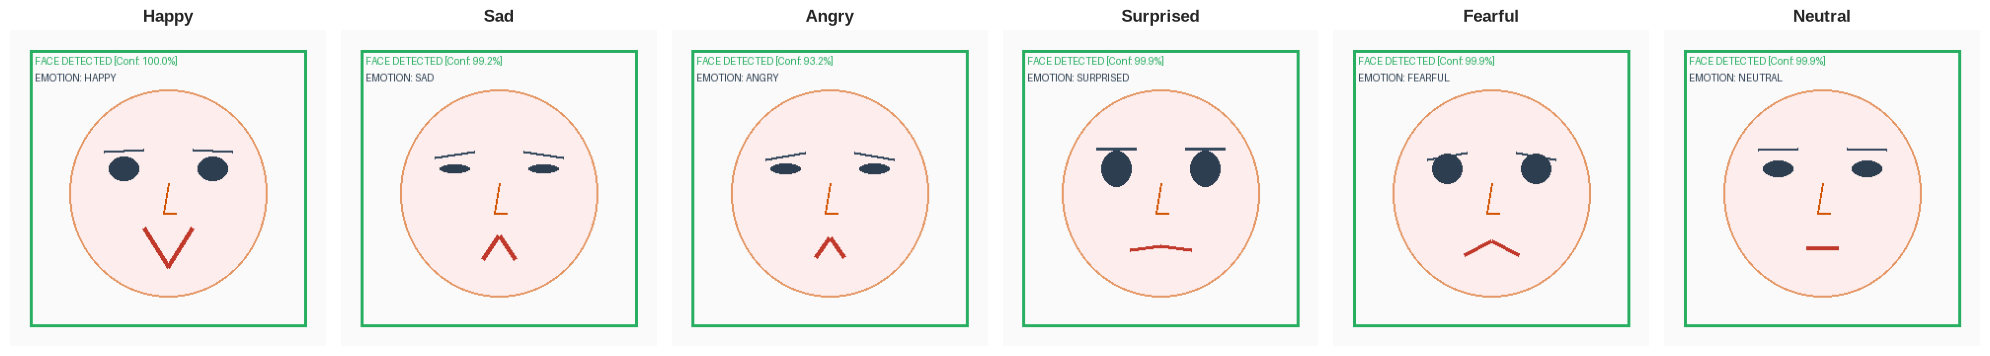

In [11]:
def render_face_expression(mouth_curve, mouth_width, brow_furrow, eye_openness, tension, predicted_emotion, conf):
    img = Image.new('RGB', (320, 320), color='#FAFAFA')
    draw = ImageDraw.Draw(img)

    draw.rectangle([(20, 20), (300, 300)], outline='#27AE60', width=3)
    draw.text((25, 25), f"FACE DETECTED [Conf: {conf:.1f}%]", fill='#27AE60')
    draw.text((25, 42), f"EMOTION: {predicted_emotion.upper()}", fill='#2C3E50')

    draw.ellipse([(60, 60), (260, 270)], fill='#FDEDEC', outline='#E59866', width=2)

    brow_y = 120 + int(brow_furrow * 15)
    draw.line([(95, brow_y), (135, brow_y - int(brow_furrow * 10))], fill='#34495E', width=3)
    draw.line([(185, brow_y - int(brow_furrow * 10)), (225, brow_y)], fill='#34495E', width=3)

    eye_h = max(3, int(eye_openness * 18))
    draw.ellipse([(100, 140 - eye_h), (130, 140 + eye_h)], fill='#2C3E50')
    draw.ellipse([(190, 140 - eye_h), (220, 140 + eye_h)], fill='#2C3E50')

    draw.line([(160, 155), (155, 185), (168, 185)], fill='#D35400', width=2)

    m_w = int(mouth_width * 40)
    m_c = int(mouth_curve * 25)
    cx, cy = 160, 220
    draw.line([(cx - m_w, cy - m_c), (cx, cy + m_c), (cx + m_w, cy - m_c)], fill='#C0392B', width=4)

    return img

sample_faces = []
for em in ['Happy', 'Sad', 'Angry', 'Surprised', 'Fearful', 'Neutral']:
    sample_row = df_emotions[df_emotions['emotion'] == em].iloc[0]
    feats = np.array([[sample_row['mouth_curve'], sample_row['mouth_width'], sample_row['brow_furrow'], sample_row['eye_openness'], sample_row['tension']]])
    pred_prob = emotion_classifier.predict_proba(feats)[0]
    pred_em = emotion_classifier.classes_[np.argmax(pred_prob)]
    conf = np.max(pred_prob) * 100

    face_img = render_face_expression(
        sample_row['mouth_curve'], sample_row['mouth_width'], sample_row['brow_furrow'],
        sample_row['eye_openness'], sample_row['tension'], pred_em, conf
    )
    sample_faces.append((em, face_img))

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, (em, f_img) in zip(axes, sample_faces):
    ax.imshow(f_img)
    ax.set_title(em, fontsize=12, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()


In [12]:
class EmotionAwareCognitiveAssistant:
    def __init__(self, classifier, feature_names):
        self.classifier = classifier
        self.feature_names = feature_names

    def perceive_emotion(self, biometric_features):
        probs = self.classifier.predict_proba([biometric_features])[0]
        max_idx = np.argmax(probs)
        emotion = self.classifier.classes_[max_idx]
        confidence = probs[max_idx]
        return emotion, confidence, probs

    def generate_response(self, user_query, biometric_features):
        detected_emotion, conf, probs = self.perceive_emotion(biometric_features)

        if detected_emotion == 'Happy':
            tone = "🌟 Celebratory & Enthusiastic"
            prefix = "It is wonderful to see you in such fantastic spirits!"
            empathy_note = "Your positive energy is contagious! Let's build on this great momentum."

        elif detected_emotion == 'Sad':
            tone = "💙 Warm, Empathetic & Compassionate"
            prefix = "I notice that you seem down or carrying a heavy weight today."
            empathy_note = "I want you to know I'm here to support you. Take all the time you need, and don't hesitate to take a gentle pause."

        elif detected_emotion == 'Angry':
            tone = "🛡️ De-escalating, Calm & Direct"
            prefix = "I can sense your frustration, and I completely understand why you might feel this way."
            empathy_note = "Let's strip away all the complexity and solve this issue directly and efficiently for you right now."

        elif detected_emotion == 'Fearful':
            tone = "🤝 Grounding, Reassuring & Structured"
            prefix = "I sense some anxiety or apprehension in your expression."
            empathy_note = "Take a slow, deep breath. You are in safe hands, and we will take this step-by-step together."

        elif detected_emotion == 'Surprised':
            tone = "💡 Engaging & Explanatory"
            prefix = "That caught you by surprise, didn't it!"
            empathy_note = "Let me break down the details so everything is completely crystal clear."

        else:
            tone = "📋 Professional, Attentive & Objective"
            prefix = "Understood. I am ready to assist you."
            empathy_note = "Here is the concise information you requested."

        q_lower = user_query.lower()
        if 'project' in q_lower or 'deadline' in q_lower or 'work' in q_lower:
            core_answer = "For your workload, prioritize your tasks into the Eisenhower matrix (urgent vs important). Break larger milestones into 25-minute Pomodoro sprints."
        elif 'exam' in q_lower or 'score' in q_lower or 'grade' in q_lower or 'study' in q_lower:
            core_answer = "Academic results reflect a single snapshot, not your potential. Review the specific concepts you found tricky, make active recall flashcards, and give yourself adequate rest."
        elif 'error' in q_lower or 'bug' in q_lower or 'system' in q_lower or 'not working' in q_lower:
            core_answer = "I have logged the diagnostic traces. Let's isolate the issue by checking recent commits, verifying dependency versions, and running unit test suites."
        elif 'promot' in q_lower or 'success' in q_lower or 'win' in q_lower or 'passed' in q_lower:
            core_answer = "Congratulations on this outstanding milestone! Recognizing your hard work is vital for sustained growth."
        else:
            core_answer = f"Regarding '{user_query}': I am analyzing the relevant context and have prepared actionable steps tailored to your situation."

        return {
            'detected_emotion': detected_emotion,
            'confidence': conf,
            'tone': tone,
            'response': f"{prefix}\n{empathy_note}\n\n👉 Assistance: {core_answer}"
        }


In [13]:
assistant = EmotionAwareCognitiveAssistant(emotion_classifier, ['mouth_curve', 'mouth_width', 'brow_furrow', 'eye_openness', 'tension'])

test_interactions = [
    {
        'scenario': 'User is celebrating a major achievement',
        'query': "I passed my cognitive computing exam with the top grade!",
        'features': [0.80, 0.68, 0.12, 0.58, 0.18]
    },
    {
        'scenario': 'User is experiencing distress over a setback',
        'query': "I just failed my project review and feel terrible.",
        'features': [-0.70, 0.32, 0.65, 0.28, 0.42]
    },
    {
        'scenario': 'User is frustrated with a technical bug',
        'query': "Your system keeps throwing errors and nothing is working!",
        'features': [-0.40, 0.36, 0.88, 0.34, 0.89]
    },
    {
        'scenario': 'User is anxious about an impending deadline',
        'query': "I have three project deadlines tonight and I feel completely overwhelmed.",
        'features': [-0.22, 0.72, 0.78, 0.82, 0.84]
    },
    {
        'scenario': 'User is asking a routine operational question',
        'query': "Can you summarize the project status report for the team?",
        'features': [0.01, 0.44, 0.24, 0.49, 0.24]
    }
]

print("=" * 85)
print("EMOTION-AWARE COGNITIVE ASSISTANT MULTIMODAL DIALOGUE EVALUATION")
print("=" * 85)

for i, test in enumerate(test_interactions, 1):
    res = assistant.generate_response(test['query'], test['features'])
    print(f"\n[SCENARIO {i}]: {test['scenario']}")
    print(f"[USER QUERY]: \"{test['query']}\"")
    print(f"[DETECTED EMOTION]: {res['detected_emotion']} (Confidence: {res['confidence']*100:.1f}%)")
    print(f"[CONVERSATIONAL TONE]: {res['tone']}")
    print(f"[ASSISTANT RESPONSE]:\n{res['response']}")
    print("-" * 85)


EMOTION-AWARE COGNITIVE ASSISTANT MULTIMODAL DIALOGUE EVALUATION

[SCENARIO 1]: User is celebrating a major achievement
[USER QUERY]: "I passed my cognitive computing exam with the top grade!"
[DETECTED EMOTION]: Happy (Confidence: 100.0%)
[CONVERSATIONAL TONE]: 🌟 Celebratory & Enthusiastic
[ASSISTANT RESPONSE]:
It is wonderful to see you in such fantastic spirits!
Your positive energy is contagious! Let's build on this great momentum.

👉 Assistance: Academic results reflect a single snapshot, not your potential. Review the specific concepts you found tricky, make active recall flashcards, and give yourself adequate rest.
-------------------------------------------------------------------------------------

[SCENARIO 2]: User is experiencing distress over a setback
[USER QUERY]: "I just failed my project review and feel terrible."
[DETECTED EMOTION]: Sad (Confidence: 100.0%)
[CONVERSATIONAL TONE]: 💙 Warm, Empathetic & Compassionate
[ASSISTANT RESPONSE]:
I notice that you seem down or c